In [29]:
import pandas as pd

# Código da série do IPCA no Sistema do Banco Central
codigo_serie = 433
url = f'https://api.bcb.gov.br/dados/serie/bcdata.sgs.{codigo_serie}/dados?formato=json'

# Consumindo a API diretamente
df_ipca = pd.read_json(url)

# Convertendo a coluna 'data' para o formato datetime
df_ipca['data'] = pd.to_datetime(df_ipca['data'], format='%d/%m/%Y') #necessary for time series

df_ipca = df_ipca[(df_ipca['data'] >= '2000-01-01') & (df_ipca['data'] < '2026-01-01')].reset_index(drop=True)



print(df_ipca.shape)
print(f"Valores negativos: {(df_ipca['valor'] < 0).sum()}")
print(f"Valores zero: {(df_ipca['valor'] == 0).sum()}")

# Visualizando as primeiras linhas
print(df_ipca.head())
print(df_ipca.tail())
print(df_ipca.value_counts().sum())
print(df_ipca.isnull().sum())

(312, 2)
Valores negativos: 15
Valores zero: 1
        data  valor
0 2000-01-01   0.62
1 2000-02-01   0.13
2 2000-03-01   0.22
3 2000-04-01   0.42
4 2000-05-01   0.01
          data  valor
307 2025-08-01  -0.11
308 2025-09-01   0.48
309 2025-10-01   0.09
310 2025-11-01   0.18
311 2025-12-01   0.33
312
data     0
valor    0
dtype: int64


In [30]:
import plotly.express as px
def plotting(title, data, x, y, x_label, y_label ):
    fig = px.line(data, x=df_ipca[x], y=df_ipca[y], labels={x: x_label, y: y_label})

    fig.update_layout(template='simple_white', font=dict(size=18), title_text = title, width=650, title_x = 0.5, height = 400)

    fig.show()


In [31]:
plotting('IPCA', df_ipca, 'data', 'valor', 'Date', 'Values')

<Figure size 1000x500 with 0 Axes>

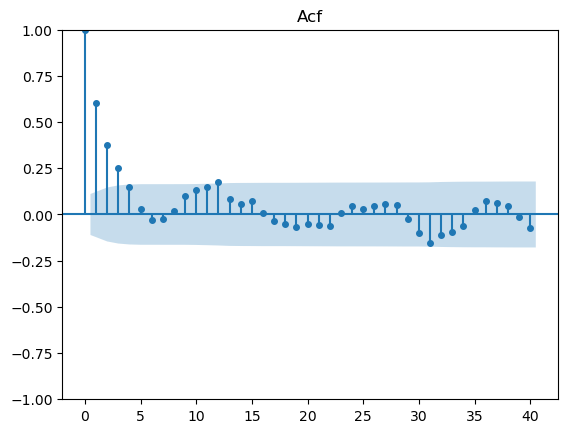

In [32]:
from statsmodels.graphics.tsaplots import plot_acf
from matplotlib import pyplot as plt
valore = df_ipca['valor']
plt.figure(figsize=(10, 5))
plot_acf(valore, lags=40, markersize=4)
plt.title('Acf')
plt.show()

In [33]:
print(df_ipca['valor'].describe())
print(f"Valores negativos: {(df_ipca['valor'] < 0).sum()}")
print(f"Valores zero: {(df_ipca['valor'] == 0).sum()}")

count    312.000000
mean       0.495288
std        0.393914
min       -0.680000
25%        0.250000
50%        0.445000
75%        0.655000
max        3.020000
Name: valor, dtype: float64
Valores negativos: 15
Valores zero: 1


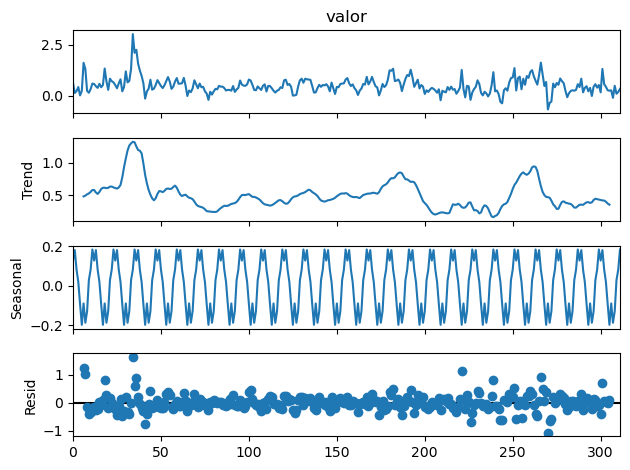

In [35]:
from statsmodels.tsa.seasonal import seasonal_decompose

decompose = seasonal_decompose(df_ipca['valor'], model='additive', period=12)
decompose.plot()
plt.show()